# F3 · Madde 1 (ve Madde 5) — Aşama 5–9'un 10 tohumla tekrarı, tüm performans metrikleri
**Profesörün notu:** *Aşama 5–9 deneylerini 10 farklı tohumla tekrarlayıp tüm performans metriklerini raporla.*
*Risk–Coverage, FPR, recall ve selective risk sonuçlarını tüm modeller için tamamla.*

Her tohum (0–9) için, 02 defterinde **aynı tohumla eğitilen** merkezi AE kullanılır:
* **Aşama 5–6 (FL):** istemci bölmeleri tohuma göre çekilir; protokoller `cfg.fl_final_protocols` (F1 teşhisinden sonra
  sabitlenir; varsayılan: ara dönem protokolü + yakınsama/Adam korunur + FedProx); yalnız yerel eğitim; iki kalibrasyon.
* **Aşama 7 (TinyML):** merkezi AE ve FedAvg-IID modelleri → TFLite FP32/INT8; boyut, kaba RAM tahmini, gecikme
  (**Colab CPU'sunda; mikrodenetleyici ölçümü değildir**), FP32↔INT8 skor uyumu, eşik geçerliliği.
* **Aşama 8 (sağlamlık):** gürültü, eksik öznitelik ve bozuk öznitelik (plandaki üç senaryo), 3 tekrar, devralınan eşik /
  yeniden kalibrasyon; her deneyde F1, FPR, görülmemiş recall, kapsama ve seçici risk.
* **Aşama 9 (ablasyon):** A1–A6; her yapılandırma için FPR, recall, precision, F1, ANOMALY/UNCERTAIN/kaçan, kapsama,
  seçici risk (test kümesi ve π = %1); her model için risk–kapsama eğrisi.
* İstemci bazında sonuçlar (`fl_istemci`) ve FP32/INT8 model dosyaları (`artifacts/final_f3/tflite/`) da kaydedilir.

Raporlama: ortalama, standart sapma, tohumlar üzerinden bootstrap %95 GA, eşleştirilmiş Wilcoxon + Holm.
Güven aralıkları yalnız **eğitim tohumu** değişkenliğini yansıtır (veri bölmesi sabittir).

In [1]:
# ---- Kurulum (her defterde aynı): Drive'ı bağla, ortak kodu içe aktar ----
import os, sys
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
PROJECT_DIR = os.environ.get("TRUSTIDS_PROJECT", "/content/drive/MyDrive/TrustFed-TinyIDS-Final")
QUICK = os.environ.get("TRUSTIDS_QUICK", "0") == "1"   # hızlı mod YALNIZCA kodu test etmek içindir
# Devam modu: Colab oturumu kapanırsa, Drive'a kaydedilmiş tohumlar/adımlar atlanır ve kalan yerden devam edilir.
# Her şeyi baştan hesaplamak için: os.environ["TRUSTIDS_RESUME"] = "0"
RESUME = os.environ.get("TRUSTIDS_RESUME", "1") == "1"
sys.path.insert(0, PROJECT_DIR)

from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from trustids.config import Config
from trustids import utils

# Veri kümesi seçimi: varsayılan TON_IoT; ikinci veri kümesi için TRUSTIDS_CONFIG=edge_iiotset.json
CONFIG_NAME = os.environ.get("TRUSTIDS_CONFIG", "default.json")
CFG_PATH = Path(PROJECT_DIR) / "configs" / CONFIG_NAME
if CONFIG_NAME != "default.json" and not CFG_PATH.exists():
    raise FileNotFoundError(f"{CFG_PATH} bulunamadı: configs/ klasörünü de Drive'a yükleyin.")
cfg = Config.load(CFG_PATH) if CFG_PATH.exists() else Config(project_dir=PROJECT_DIR)
cfg.project_dir = PROJECT_DIR
if QUICK:
    cfg.train_seeds, cfg.validity_resplits, cfg.epochs = cfg.train_seeds[:2], 30, 15
    cfg.random_control_repeats, cfg.bootstrap_repeats = 10, 200
    cfg.lofo_seeds, cfg.fl_orig_rounds = cfg.lofo_seeds[:2], 3
    cfg.resolution_cal_windows, cfg.resolution_eval_windows = 600, 600
cfg.check()
ART = cfg.artifacts
FIG = Path(PROJECT_DIR) / cfg.figures_dir; FIG.mkdir(exist_ok=True)
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
print("Proje klasörü:", PROJECT_DIR, "| hızlı mod:", QUICK, "| devam modu:", RESUME)
print("Drive'da kayıtlı ilerleme:", utils.progress(cfg))

Mounted at /content/drive
Proje klasörü: /content/drive/MyDrive/TrustFed-TinyIDS-Final | hızlı mod: False | devam modu: True
Drive'da kayıtlı ilerleme: {'01_hazirlanan_veri': True, '02_tohumlar_tamam': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], '02_oznitelik_karsilastirma_tohumlari': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], '03_kararlar': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], '04b_host_eslesmesi': True}


In [2]:
import tensorflow as tf
from trustids import data as D, models as M, conformal as C, evaluation as E, fl as FL, tiny as TY, final as FZ, pipeline as PL
print(TY.self_test())                       # TFLite bu ortamda çalışıyor mu? (saatler süren eğitimden ÖNCE kontrol)
P = D.load_prepared(ART / "prepared"); X = P["X"]; FNAMES = P["preprocessor"].feature_names_
CHOSEN = utils.load_json(ART / "ae_selection.json")["chosen"]; spec = cfg.ae_variants[CHOSEN]
TAG = "F3"
CACHE = ART / "final_f3"; CACHE.mkdir(exist_ok=True)
FP = utils.fingerprint(cfg, ["fl_clients", "fl_scenarios", "fl_orig_rounds", "fl_local_epochs", "fl_fedprox_mu",
                             "fl_final_protocols", "alpha", "beta"])
RUN = utils.new_run_dir(Path(PROJECT_DIR) / cfg.runs_dir, "final_F3_asama5_9")
utils.save_json(utils.environment_info(), RUN / "environment.json"); cfg.save(RUN / "config_used.json")
d_in = X["benign_train"].shape[1]
def build(): return M.build_autoencoder(d_in, spec["hidden"], spec["dropout"], cfg.learning_rate)
CAT = {sp: FL.service_categories(X[sp], FNAMES) for sp in ["benign_train", "benign_val", "benign_cal", "benign_test"]}
COLL = P["collision"]["heldout_test"]
SEEDS = [s for s in cfg.train_seeds if (ART / "models" / f"ae_seed{s}.keras").exists() and E.scores_path(cfg, s).exists()]
missing = sorted(set(cfg.train_seeds) - set(SEEDS))
if missing: print("UYARI: bu tohumların merkezi modeli yok, önce 02 defterini tamamlayın:", missing)
def seed_inputs(seed):
    S = E.load_scores(cfg, seed)
    pick = lambda m: {sp: S[(m, sp)] for sp in PL.EV}
    return dict(central=tf.keras.models.load_model(ART / "models" / f"ae_seed{seed}.keras", compile=False),
                base=pick("ae"), iforest=pick("iforest"), latent=pick("latent"))
print("öznitelik:", d_in, "| tohumlar:", SEEDS, "| protokoller:", cfg.fl_final_protocols, "| parmak izi:", FP, "| sonuç:", RUN)

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


TFLite dönüştürme ve INT8 çalıştırma testi geçti (TensorFlow 2.21.0)
öznitelik: 53 | tohumlar: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] | protokoller: ['orijinal', 'orijinal_kucuk_yigin', 'yakinsama_kalici', 'fedprox_kalici'] | parmak izi: cf1bc800edc0 | sonuç: /content/drive/MyDrive/TrustFed-TinyIDS-Final/runs/20261112-060216_final_F3_asama5_9


## Çalıştırma (her FL modeli ve her tohum Drive'a kaydedilir; oturum kapanırsa kaldığı yerden devam eder)

In [3]:
for seed in SEEDS:
    f = CACHE / f"seed{seed}_{FP}.json"
    if RESUME and f.exists():
        print("tohum", seed, "Drive'da kayıtlı, atlanıyor (devam modu)"); continue
    print("tohum", seed, "çalışıyor...", flush=True)
    res = PL.run_seed(seed, cfg=cfg, X=X, cats=CAT, build=build, cache_dir=CACHE, fp=FP, resume=RESUME, coll_ho=COLL,
                      **seed_inputs(seed))
    utils.save_json(res, f)
    print("tohum", seed, "tamam (Drive'a kaydedildi)", flush=True)

tohum 0 Drive'da kayıtlı, atlanıyor (devam modu)
tohum 1 Drive'da kayıtlı, atlanıyor (devam modu)
tohum 2 Drive'da kayıtlı, atlanıyor (devam modu)
tohum 3 Drive'da kayıtlı, atlanıyor (devam modu)
tohum 4 Drive'da kayıtlı, atlanıyor (devam modu)
tohum 5 Drive'da kayıtlı, atlanıyor (devam modu)
tohum 6 Drive'da kayıtlı, atlanıyor (devam modu)
tohum 7 Drive'da kayıtlı, atlanıyor (devam modu)
tohum 8 Drive'da kayıtlı, atlanıyor (devam modu)
tohum 9 çalışıyor...
  tohum 9: FL IID / orijinal tamam (40 tur, fixed_rounds)
  tohum 9: FL IID / orijinal_kucuk_yigin tamam (40 tur, fixed_rounds)
  tohum 9: FL IID / yakinsama_kalici tamam (300 tur, epoch_cap)
  tohum 9: FL IID / fedprox_kalici tamam (300 tur, epoch_cap)
  tohum 9: FL Dirichlet=1.0 / orijinal tamam (40 tur, fixed_rounds)
  tohum 9: FL Dirichlet=1.0 / orijinal_kucuk_yigin tamam (40 tur, fixed_rounds)
  tohum 9: FL Dirichlet=1.0 / yakinsama_kalici tamam (204 tur, relative_plateau)
  tohum 9: FL Dirichlet=1.0 / fedprox_kalici tamam (300

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT i

tohum 9 tamam (Drive'a kaydedildi)


## Toplama: tüm tohumlar

In [4]:
T, DONE = PL.collect(CACHE, SEEDS, FP)
for k, df in T.items(): df.to_csv(RUN / f"{TAG}_{k}_tum_tohumlar.csv", index=False)
print("tamamlanan tohumlar:", DONE)

tamamlanan tohumlar: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


### Aşama 5–6 · FL (tohumlar üzerinden ortalama; testler eşleştirilmiş Wilcoxon + Holm)
`istemci_FPR_en_kötü` çok küçük bir istemciden gelebilir; bu yüzden istemci boyutuyla ağırlıklı oran da verilir. `atlanan_istemci`: verisi olmadığı için değerlendirilemeyen istemci sayısı (non-IID bölmelerde olabilir).

In [5]:
flc = ["istemci_FPR_ort", "istemci_FPR_ağırlıklı", "istemci_FPR_en_kötü", "görülmemiş_ANOMALY", "görülmemiş_UNCERTAIN", "görülmemiş_kaçan",
       "bilinen_ANOMALY", "precision_görülmemiş", "recall_görülmemiş", "f1_görülmemiş", "coverage", "selective_risk", "atlanan_istemci"]
FLS = FZ.seed_summary(T["fl"], ["model", "senaryo", "kalibrasyon"], flc, cfg.bootstrap_repeats); FLS.to_csv(RUN / f"{TAG}_fl_ozet.csv", index=False)
EGS = T["egitim"].groupby(["senaryo", "protokol"])[["rounds_run", "epochs_equivalent", "local_steps_mean", "comm_MB", "val_loss_best"]].agg(["mean", "std"]).round(3)
EGS.to_csv(RUN / f"{TAG}_fl_egitim_ozet.csv"); display(EGS)
T["fl"]["konfig"] = T["fl"]["model"] + " | " + T["fl"]["senaryo"] + " | " + T["fl"]["kalibrasyon"]
pairs = [(f"Merkezi (yakınsama) | {s} | havuz skor", f"FedAvg · {p} | {s} | havuz skor") for s in cfg.fl_scenarios for p in cfg.fl_final_protocols]
FLT = pd.concat([FZ.paired_tests(T["fl"], "konfig", pairs, mt) for mt in ["görülmemiş_ANOMALY", "bilinen_ANOMALY", "selective_risk"]])
FLT.to_csv(RUN / f"{TAG}_fl_testler.csv", index=False)
FLS[FLS["metrik"].isin(["görülmemiş_ANOMALY", "bilinen_ANOMALY", "istemci_FPR_ağırlıklı", "istemci_FPR_en_kötü", "selective_risk"])].pivot_table(
    index=["model", "senaryo", "kalibrasyon"], columns="metrik", values="ortalama").round(4)

rounds_run         epochs_equivalent          local_steps_mean           comm_MB         val_loss_best       
                                         mean     std              mean      std             mean       std    mean     std          mean    std
senaryo       protokol                                                                                                                          
Dirichlet=0.1 fedprox_kalici            282.7  28.868            1413.5  144.339           5306.7   486.672  54.606   5.576         0.003  0.001
              orijinal                   40.0   0.000             200.0    0.000            752.0    25.298   7.726   0.000         0.009  0.008
              orijinal_kucuk_yigin       40.0   0.000             200.0    0.000           3340.0    28.284   7.726   0.000         0.007  0.007
              yakinsama_kalici          151.7  69.073             758.5  345.367           2868.4  1332.154  29.302  13.342         0.004  0.003
Dirichlet=1.0 fedprox_kalici            300.0   0.000            1500.0    0.000           5670.0   170.294  57.948   0.000         0.002  0.000
              orijinal                   40.0   0.000             200.0    0.000            756.0    22.706   7.726   0.000         0.004  0.001
              orijinal_kucuk_yigin       40.0   0.000             200.0    0.000           3356.0    12.649   7.726   0.000         0.002  0.000
              yakinsama_kalici          278.4  37.465            1392.0  187.323           5251.5   648.668  53.776   7.237         0.001  0.000
IID           fedprox_kalici            300.0   0.000            1500.0    0.000           6000.0     0.000  57.948   0.000         0.002  0.000
              orijinal                   40.0   0.000             200.0    0.000            800.0     0.000   7.726   0.000         0.004  0.001
              orijinal_kucuk_yigin       40.0   0.000             200.0    0.000           3400.0     0.000   7.726   0.000         0.002  0.000
              yakinsama_kalici          300.0   0.000            1500.0    0.000           6000.0     0.000  57.948   0.000         0.001  0.000

metrik                                                      bilinen_ANOMALY  görülmemiş_ANOMALY  istemci_FPR_ağırlıklı  istemci_FPR_en_kötü  selective_risk
model                         senaryo       kalibrasyon                                                                                                    
FedAvg · fedprox_kalici       Dirichlet=0.1 havuz skor               0.0343              0.2266                 0.0097               0.1719          0.8546
                                            istemci başına           0.0924              0.2119                 0.0064               0.0099          0.7823
                              Dirichlet=1.0 havuz skor               0.0489              0.2208                 0.0065               0.0175          0.8433
                                            istemci başına           0.0513              0.2135                 0.0063               0.0102          0.8392
                              IID           havuz skor               0.0419              0.3113                 0.0064               0.0100          0.8203
                                            istemci başına           0.0353              0.2071                 0.0058               0.0108          0.8644
FedAvg · orijinal             Dirichlet=0.1 havuz skor               0.0065              0.0043                 0.0105               0.1688          0.9603
                                            istemci başına           0.0786              0.1545                 0.0064               0.0086          0.8230
                              Dirichlet=1.0 havuz skor               0.0110              0.0630                 0.0077               0.0223          0.9395
                                            istemci başına           0.0196              0.1113                 0.0074               0.0118          0.9153
                              IID           havuz skor               0.0066              0.0210                 0.0080               0.0114          0.9579
                                            istemci başına           0.0059              0.0138                 0.0070               0.0113          0.9617
FedAvg · orijinal_kucuk_yigin Dirichlet=0.1 havuz skor               0.0095              0.0650                 0.0097               0.1561          0.9357
                                            istemci başına           0.1052              0.1793                 0.0070               0.0100          0.8011
                              Dirichlet=1.0 havuz skor               0.0570              0.3066                 0.0067               0.0182          0.7953
                                            istemci başına           0.0558              0.2294                 0.0062               0.0103          0.8304
                              IID           havuz skor               0.0579              0.2852                 0.0064               0.0099          0.8071
                                            istemci başına           0.0467              0.2044                 0.0058               0.0112          0.8474
FedAvg · yakinsama_kalici     Dirichlet=0.1 havuz skor               0.0508              0.1127                 0.0093               0.1508          0.8584
                                            istemci başına           0.1236              0.2104                 0.0059               0.0080          0.7517
                              Dirichlet=1.0 havuz skor               0.1064              0.3570                 0.0073               0.0217          0.7179
                                            istemci başına           0.0877              0.2675                 0.0074               0.0124          0.7847
                              IID           havuz skor               0.1267              0.4012                 0.0070               0.0108          0.6821
                                            istemci başına           0.1070              0.3268     

In [6]:
FLT.round(4)

,a,b,metrik,ortalama_fark_a-b,a_daha_büyük_tohum,tohum,p_raw,p_holm
0,Merkezi (yakınsama) | IID | havuz skor,FedAvg · orijinal | IID | havuz skor,görülmemiş_ANOMALY,0.4348,10,10,0.0020,0.0234
1,Merkezi (yakınsama) | Dirichlet=1.0 | havuz skor,FedAvg · fedprox_kalici | Dirichlet=1.0 | havu...,görülmemiş_ANOMALY,0.2351,10,10,0.0020,0.0234
2,Merkezi (yakınsama) | Dirichlet=1.0 | havuz skor,FedAvg · orijinal_kucuk_yigin | Dirichlet=1.0 ...,görülmemiş_ANOMALY,0.1492,10,10,0.0020,0.0234
3,Merkezi (yakınsama) | Dirichlet=1.0 | havuz skor,FedAvg · orijinal | Dirichlet=1.0 | havuz skor,görülmemiş_ANOMALY,0.3929,10,10,0.0020,0.0234
4,Merkezi (yakınsama) | Dirichlet=0.1 | havuz skor,FedAvg · fedprox_kalici | Dirichlet=0.1 | havu...,görülmemiş_ANOMALY,0.2293,10,10,0.0020,0.0234
5,Merkezi (yakınsama) | Dirichlet=0.1 | havuz skor,FedAvg · yakinsama_kalici | Dirichlet=0.1 | ha...,görülmemiş_ANOMALY,0.3431,10,10,0.0020,0.0234
6,Merkezi (yakınsama) | Dirichlet=0.1 | havuz skor,FedAvg · orijinal_kucuk_yigin | Dirichlet=0.1 ...,görülmemiş_ANOMALY,0.3909,10,10,0.0020,0.0234
7,Merkezi (yakınsama) | Dirichlet=0.1 | havuz skor,FedAvg · orijinal | Dirichlet=0.1 | havuz skor,görülmemiş_ANOMALY,0.4515,10,10,0.0020,0.0234
8,Merkezi (yakınsama) | Dirichlet=1.0 | havuz skor,FedAvg · yakinsama_kalici | Dirichlet=1.0 | ha...,görülmemiş_ANOMALY,0.0989,9,10,0.0059,0.0234
9,Merkezi (yakınsama) | IID | havuz skor,FedAvg · orijinal_kucuk_yigin | IID | havuz skor,görülmemiş_ANOMALY,0.1706,9,10,0.0059,0.0234


### Aşama 7 · TinyML (gecikme Colab CPU'sunda; mikrodenetleyici ölçümü değildir)

In [7]:
TYS = FZ.seed_summary(T["tiny"], ["model"], ["parametre", "tflite_fp32_KB", "tflite_int8_KB", "tahmini_RAM_KB_int8",
                                             "gecikme_fp32_µs_colab", "gecikme_int8_µs_colab", "Spearman_FP32_INT8"], cfg.bootstrap_repeats)
I8S = FZ.seed_summary(T["int8"], ["model", "kural"], ["normal_FPR", "fark_α", "normal_UNCERTAIN", "görülmemiş_ANOMALY", "görülmemiş_UNCERTAIN"], cfg.bootstrap_repeats)
TYS.to_csv(RUN / f"{TAG}_tinyml_ozet.csv", index=False); I8S.to_csv(RUN / f"{TAG}_int8_gecerlilik_ozet.csv", index=False)
display(TYS.pivot_table(index="model", columns="metrik", values="ortalama").round(3))
I8S.pivot_table(index=["model", "kural"], columns="metrik", values="ortalama").round(4)

metrik,Spearman_FP32_INT8,gecikme_fp32_µs_colab,gecikme_int8_µs_colab,parametre,tahmini_RAM_KB_int8,tflite_fp32_KB,tflite_int8_KB
model,,,,,,,
FedAvg-IID · fedprox_kalici,0.843,2.152,1.880,4829.0,4.869,22.023,12.891
FedAvg-IID · orijinal,0.978,2.092,1.797,4829.0,4.869,22.023,12.891
FedAvg-IID · orijinal_kucuk_yigin,0.901,2.137,1.781,4829.0,4.869,22.023,12.891
FedAvg-IID · yakinsama_kalici,0.756,2.379,2.019,4829.0,4.869,22.023,12.891
Merkezi AE,0.602,2.060,1.752,4829.0,4.869,22.023,12.891


metrik                                                                  fark_α  görülmemiş_ANOMALY  görülmemiş_UNCERTAIN  normal_FPR  normal_UNCERTAIN
model                             kural                                                                                                               
FedAvg-IID · fedprox_kalici       FP32 skor + FP32 eşik                -0.0036              0.3113                0.3822      0.0064            0.0411
                                  INT8 skor + INT8 yeniden kalibrasyon -0.0034              0.3217                0.3728      0.0066            0.0411
                                  INT8 skor + devralınan FP32 eşik     -0.0033              0.3182                0.3822      0.0067            0.0426
FedAvg-IID · orijinal             FP32 skor + FP32 eşik                -0.0020              0.0210                0.6128      0.0080            0.0421
                                  INT8 skor + INT8 yeniden kalibrasyon -0.0017              0.0218                0.6114      0.0083            0.0417
                                  INT8 skor + devralınan FP32 eşik     -0.0017              0.0215                0.6127      0.0083            0.0422
FedAvg-IID · orijinal_kucuk_yigin FP32 skor + FP32 eşik                -0.0036              0.2852                0.4096      0.0064            0.0417
                                  INT8 skor + INT8 yeniden kalibrasyon -0.0036              0.2592                0.4365      0.0064            0.0418
                                  INT8 skor + devralınan FP32 eşik     -0.0035              0.2824                0.4154      0.0065            0.0429
FedAvg-IID · yakinsama_kalici     FP32 skor + FP32 eşik                -0.0030              0.4012                0.4010      0.0070            0.0407
                                  INT8 skor + INT8 yeniden kalibrasyon -0.0028              0.4123                0.3909      0.0072            0.0407
                                  INT8 skor + devralınan FP32 eşik     -0.0030              0.4000                0.4166      0.0070            0.0446
Merkezi AE                        FP32 skor + FP32 eşik                -0.0028              0.4558                0.3770      0.0072            0.0411
                                  INT8 skor + INT8 yeniden kalibrasyon -0.0025              0.4625                0.3737      0.0075            0.0407
                                  INT8 skor + devralınan FP32 eşik     -0.0022              0.4632                0.3875      0.0078            0.0631

### Aşama 8 · Sağlamlık (merkezi AE): gürültü, eksik öznitelik, bozuk öznitelik
`düzey`: gürültüde standart sapma, eksik öznitelikte eksik payı, bozuk öznitelikte bozulan öznitelik sayısı (seçilen özniteliklerin değerleri örnekler arasında karıştırılır). Her satır 3 tekrarın, sonra tohumların ortalamasıdır.

In [8]:
rob = T["rob"].groupby(["tohum", "bozulma", "düzey", "politika"], as_index=False).mean(numeric_only=True)   # önce 3 tekrarın ortalaması
RBS = FZ.seed_summary(rob, ["bozulma", "düzey", "politika"], ["normal_FPR", "normal_UNCERTAIN", "görülmemiş_ANOMALY",
                      "görülmemiş_ANOMALY+UNCERTAIN", "bilinen_ANOMALY", "f1_görülmemiş", "coverage", "selective_risk", "selective_risk_π=%1"], cfg.bootstrap_repeats)
RBS.to_csv(RUN / f"{TAG}_saglamlik_ozet.csv", index=False)
RBS.pivot_table(index=["bozulma", "düzey", "politika"], columns="metrik", values="ortalama").round(4)

metrik                                   bilinen_ANOMALY  coverage  f1_görülmemiş  görülmemiş_ANOMALY  görülmemiş_ANOMALY+UNCERTAIN  normal_FPR  \
bozulma       düzey politika                                                                                                                      
bozuk özellik 1.00  devralınan eşik               0.1848    0.7274         0.6194              0.4731                        0.8543      0.1021   
                    yeniden kalibrasyon           0.0776    0.7670         0.3142              0.2063                        0.5460      0.0088   
              3.00  devralınan eşik               0.2478    0.7298         0.6621              0.5446                        0.8898      0.2219   
                    yeniden kalibrasyon           0.0118    0.8886         0.0858              0.0473                        0.2321      0.0102   
              5.00  devralınan eşik               0.3003    0.7181         0.6957              0.6066                        0.9277      0.3523   
                    yeniden kalibrasyon           0.0106    0.9250         0.0702              0.0379                        0.1523      0.0105   
eksik         0.05  devralınan eşik               0.2938    0.7147         0.6689              0.5295                        0.8787      0.1296   
                    yeniden kalibrasyon           0.0147    0.9157         0.1002              0.0552                        0.1809      0.0106   
              0.10  devralınan eşik               0.4013    0.7103         0.7056              0.5940                        0.9131      0.2406   
                    yeniden kalibrasyon           0.0116    0.9257         0.0758              0.0416                        0.1508      0.0102   
              0.20  devralınan eşik               0.5709    0.7324         0.7580              0.7023                        0.9559      0.4231   
                    yeniden kalibrasyon           0.0096    0.9347         0.0352              0.0183                        0.1317      0.0100   
gürültü       0.01  devralınan eşik               0.1794    0.7328         0.6244              0.4619                        0.8451      0.0077   
                    yeniden kalibrasyon           0.1729    0.7357         0.6184              0.4556                        0.8314      0.0074   
              0.05  devralınan eşik               0.2413    0.3077         0.7127              0.5586                        0.9984      0.0248   
                    yeniden kalibrasyon           0.1219    0.8110         0.5160              0.3593                        0.6104      0.0075   
              0.10  devralınan eşik               0.6428    0.6669         0.8196              0.8042                        1.0000      0.4472   
                    yeniden kalibrasyon           0.0254    0.8685         0.1284              0.0719                        0.3031      0.0099   
temiz         0.00  devralınan eşik               0.1691    0.7343         0.6188              0.4558                        0.8328      0.0072   
                    yeniden kalibrasyon           0.1691    0.7343         0.6188              0.4558                        0.8328      0.0072   

metrik                                   normal_UNCERTAIN  selective_risk  selective_risk_π=%1  
bozulma       düzey politika                                                                    
bozuk özellik 1.00  devralınan eşik                0.0886          0.5663               0.1174  
                    yeniden kalibrasyon            0.0403          0.7403               0.0157  
              3.00  devralınan eşik                0.1846          0.5143               0.2834  
                    yeniden kalibrasyon            0.0414          0.8747               0.0195  
              5.00  devralınan eşik                0.2614          0.4638               0.4517  
                    yeniden kalibrasyon            0.0419          0.8855             

### Aşama 9 · Ablasyon A1–A6: tüm metrikler (ilk tablo ortalama, ikinci tablo standart sapma, üçüncü testler)
A3q = merkezi AE'nin INT8 sürümü; INT8 etkisini FL etkisinden ayırmak için eklendi.

In [9]:
abc = [c for c in T["abl"].columns if c not in ("yapılandırma", "tohum")]
ABS = FZ.seed_summary(T["abl"], ["yapılandırma"], abc, cfg.bootstrap_repeats); ABS.to_csv(RUN / f"{TAG}_ablasyon_ozet.csv", index=False)
pairs = [("A3 · AE + seçici", "A2 · AE (ikili)"), ("A3 · AE + seçici", "A3q · INT8 AE + seçici (merkezi)")]
for p in cfg.fl_final_protocols:
    pairs += [("A3 · AE + seçici", f"A5 · Federe AE + seçici · {p}"),
              (f"A5 · Federe AE + seçici · {p}", f"A4 · Federe AE (ikili) · {p}"),
              (f"A5 · Federe AE + seçici · {p}", f"A6 · INT8 Federe AE + seçici · {p}")]
ABT = pd.concat([FZ.paired_tests(T["abl"], "yapılandırma", pairs, mt)
                 for mt in ["görülmemiş_ANOMALY", "bilinen_ANOMALY", "selective_risk", "selective_risk_π=%1", "normal_FPR"]])
ABT.to_csv(RUN / f"{TAG}_ablasyon_testler.csv", index=False)
show = ["normal_FPR", "normal_UNCERTAIN", "bilinen_ANOMALY", "görülmemiş_ANOMALY", "görülmemiş_UNCERTAIN", "görülmemiş_kaçan", "recall_görülmemiş",
        "precision_görülmemiş", "precision_görülmemiş_π=%1", "f1_görülmemiş", "coverage", "selective_risk", "selective_risk_π=%1"]
display(ABS.pivot_table(index="yapılandırma", columns="metrik", values="ortalama", sort=False).reindex(columns=show).round(4))
display(ABS.pivot_table(index="yapılandırma", columns="metrik", values="std", sort=False).reindex(columns=show).round(4))
ABT.round(4)

metrik,normal_FPR,normal_UNCERTAIN,bilinen_ANOMALY,görülmemiş_ANOMALY,görülmemiş_UNCERTAIN,görülmemiş_kaçan,recall_görülmemiş,precision_görülmemiş,precision_görülmemiş_π=%1,f1_görülmemiş,coverage,selective_risk,selective_risk_π=%1
yapılandırma,,,,,,,,,,,,,
A1 · Isolation Forest,0.0131,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,NaN,1.0000,0.9102,0.0230
A2 · AE (ikili),0.0072,0.0000,0.1691,0.4558,0.0000,0.5442,0.4558,0.9940,0.3882,0.6188,1.0000,0.6816,0.0146
A3 · AE + seçici,0.0072,0.0411,0.1691,0.4558,0.3770,0.1672,0.4558,0.9940,0.3882,0.6188,0.7343,0.5727,0.0123
A3q · INT8 AE + seçici (merkezi),0.0075,0.0407,0.1721,0.4625,0.3737,0.1637,0.4625,0.9939,0.3813,0.6248,0.7371,0.5695,0.0126
A4 · Federe AE (ikili) · orijinal,0.0080,0.0000,0.0066,0.0210,0.0000,0.9790,0.0210,0.7300,0.0248,0.0386,1.0000,0.9001,0.0178
A5 · Federe AE + seçici · orijinal,0.0080,0.0421,0.0066,0.0210,0.6128,0.3662,0.0210,0.7300,0.0248,0.0386,0.7139,0.8651,0.0154
A6 · INT8 Federe AE + seçici · orijinal,0.0083,0.0417,0.0077,0.0218,0.6114,0.3668,0.0218,0.7327,0.0247,0.0400,0.7155,0.8641,0.0157
A4 · Federe AE (ikili) · orijinal_kucuk_yigin,0.0064,0.0000,0.0579,0.2852,0.0000,0.7148,0.2852,0.9903,0.2947,0.4244,1.0000,0.7981,0.0151
A5 · Federe AE + seçici · orijinal_kucuk_yigin,0.0064,0.0417,0.0579,0.2852,0.4096,0.3052,0.2852,0.9903,0.2947,0.4244,0.7310,0.7304,0.0127


metrik,normal_FPR,normal_UNCERTAIN,bilinen_ANOMALY,görülmemiş_ANOMALY,görülmemiş_UNCERTAIN,görülmemiş_kaçan,recall_görülmemiş,precision_görülmemiş,precision_görülmemiş_π=%1,f1_görülmemiş,coverage,selective_risk,selective_risk_π=%1
yapılandırma,,,,,,,,,,,,,
A1 · Isolation Forest,0.0013,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,NaN,0.0000,0.0001,0.0013
A2 · AE (ikili),0.0010,0.0000,0.0231,0.0960,0.0000,0.0960,0.0960,0.0028,0.0705,0.1076,0.0000,0.0350,0.0009
A3 · AE + seçici,0.0010,0.0017,0.0231,0.0960,0.0723,0.0244,0.0960,0.0028,0.0705,0.1076,0.0289,0.0331,0.0010
A3q · INT8 AE + seçici (merkezi),0.0009,0.0021,0.0267,0.0982,0.0912,0.0142,0.0982,0.0027,0.0682,0.1097,0.0345,0.0323,0.0009
A4 · Federe AE (ikili) · orijinal,0.0010,0.0000,0.0025,0.0399,0.0000,0.0399,0.0399,0.1428,0.0441,0.0699,0.0000,0.0115,0.0011
A5 · Federe AE + seçici · orijinal,0.0010,0.0015,0.0025,0.0399,0.0265,0.0203,0.0399,0.1428,0.0441,0.0699,0.0154,0.0183,0.0012
A6 · INT8 Federe AE + seçici · orijinal,0.0012,0.0015,0.0041,0.0412,0.0269,0.0204,0.0412,0.1509,0.0424,0.0717,0.0157,0.0190,0.0014
A4 · Federe AE (ikili) · orijinal_kucuk_yigin,0.0005,0.0000,0.0511,0.1509,0.0000,0.1509,0.1509,0.0044,0.1023,0.1774,0.0000,0.0665,0.0006
A5 · Federe AE + seçici · orijinal_kucuk_yigin,0.0005,0.0022,0.0511,0.1509,0.1320,0.0366,0.1509,0.0044,0.1023,0.1774,0.0347,0.0846,0.0005


,a,b,metrik,ortalama_fark_a-b,a_daha_büyük_tohum,tohum,p_raw,p_holm
0,A3 · AE + seçici,A5 · Federe AE + seçici · orijinal,görülmemiş_ANOMALY,0.4348,10,10,0.0020,0.0273
1,A3 · AE + seçici,A5 · Federe AE + seçici · orijinal_kucuk_yigin,görülmemiş_ANOMALY,0.1706,9,10,0.0059,0.0762
2,A3 · AE + seçici,A5 · Federe AE + seçici · fedprox_kalici,görülmemiş_ANOMALY,0.1445,9,10,0.0273,0.3281
3,A5 · Federe AE + seçici · yakinsama_kalici,A6 · INT8 Federe AE + seçici · yakinsama_kalici,görülmemiş_ANOMALY,-0.0112,1,10,0.0488,0.5371
4,A5 · Federe AE + seçici · fedprox_kalici,A6 · INT8 Federe AE + seçici · fedprox_kalici,görülmemiş_ANOMALY,-0.0104,3,10,0.0645,0.6445
...,...,...,...,...,...,...,...,...
9,A5 · Federe AE + seçici · orijinal_kucuk_yigin,A4 · Federe AE (ikili) · orijinal_kucuk_yigin,normal_FPR,0.0000,0,10,1.0000,1.0000
10,A3 · AE + seçici,A2 · AE (ikili),normal_FPR,0.0000,0,10,1.0000,1.0000
11,A5 · Federe AE + seçici · orijinal,A4 · Federe AE (ikili) · orijinal,normal_FPR,0.0000,0,10,1.0000,1.0000
12,A5 · Federe AE + seçici · yakinsama_kalici,A4 · Federe AE (ikili) · yakinsama_kalici,normal_FPR,0.0000,0,10,1.0000,1.0000


### Madde 5 · Risk–kapsama eğrileri: tüm modeller (α sabit, β taranır)
Her modelin eğrisi sabit kapsama düzeylerinde okunur ve tohumlar üzerinden ortalanır. Bir modelin ulaşamadığı kapsama düzeyi boş bırakılır. π = %1 paneli saldırının nadir olduğu senaryodur (yeniden ağırlıklandırma).

kapsama,0.50,0.55,0.60,0.65,0.70,0.75,0.80,0.85,0.90,0.95,1.00
model,,,,,,,,,,,
Isolation Forest,0.8535,0.8657,0.8755,0.8833,0.8893,0.8948,0.8985,0.9030,0.9072,0.9110,0.9102
AE merkezi,0.4006,0.4498,0.4930,0.5290,0.5599,0.5801,0.6042,0.6265,0.6466,0.6652,0.6816
AE gizil skor,0.8369,0.8500,0.8621,0.8723,0.8811,0.8884,0.8947,0.9003,0.9041,0.9047,0.9048
AE merkezi INT8,0.3955,0.4460,0.4860,0.5223,0.5531,0.5757,0.5998,0.6225,0.6431,0.6615,0.6780
Federe AE · orijinal,0.8285,0.8333,0.8454,0.8562,0.8635,0.8701,0.8776,0.8840,0.8900,0.8957,0.9001
Federe AE INT8 · orijinal,0.8268,0.8318,0.8443,0.8549,0.8623,0.8690,0.8765,0.8830,0.8891,0.8947,0.8992
Federe AE · orijinal_kucuk_yigin,0.6389,0.6609,0.6805,0.7009,0.7185,0.7352,0.7500,0.7635,0.7762,0.7876,0.7981
Federe AE INT8 · orijinal_kucuk_yigin,0.6525,0.6742,0.6921,0.7119,0.7288,0.7453,0.7592,0.7723,0.7845,0.7955,0.8055
Federe AE · yakinsama_kalici,0.4837,0.5281,0.5640,0.5934,0.6167,0.6344,0.6559,0.6760,0.6936,0.7091,0.7234


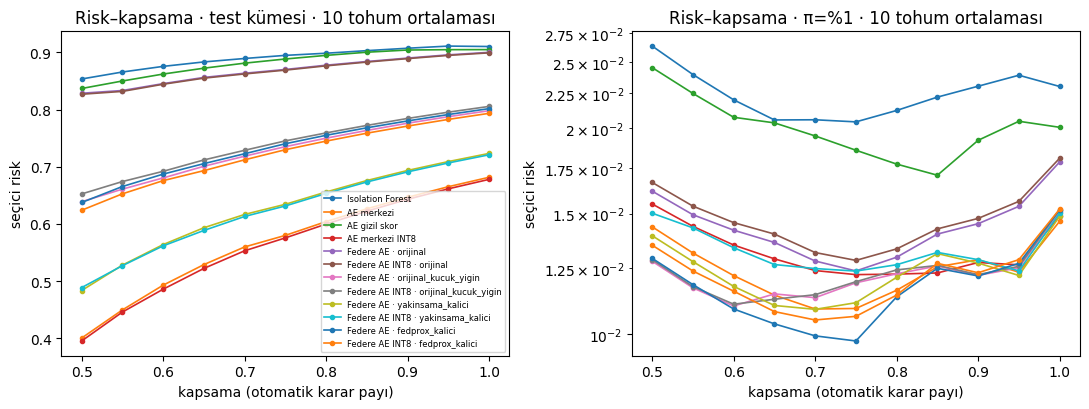

In [10]:
RCS = T["rc"].groupby(["model", "yaygınlık", "kapsama"], sort=False)["seçici_risk"].agg(["mean", "std", "count"]).reset_index()
RCS.to_csv(RUN / f"{TAG}_risk_kapsama_ozet.csv", index=False)
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, prev in zip(axs, ["test kümesi", "π=%1"]):
    for name, g in RCS[RCS["yaygınlık"] == prev].groupby("model", sort=False):
        g = g.dropna(subset=["mean"])
        ax.plot(g["kapsama"], g["mean"], marker="o", ms=3, lw=1.2, label=name)
    ax.set_xlabel("kapsama (otomatik karar payı)"); ax.set_ylabel("seçici risk"); ax.set_title(f"Risk–kapsama · {prev} · {len(DONE)} tohum ortalaması")
axs[1].set_yscale("log"); axs[0].legend(fontsize=6)
fig.tight_layout(); fig.savefig(RUN / f"{TAG}_risk_kapsama.png", dpi=150)
RCS[RCS["yaygınlık"] == "test kümesi"].pivot_table(index="model", columns="kapsama", values="mean", sort=False).round(4)

Sonuçlar: /content/drive/MyDrive/TrustFed-TinyIDS-Final/runs/20261112-060216_final_F3_asama5_9


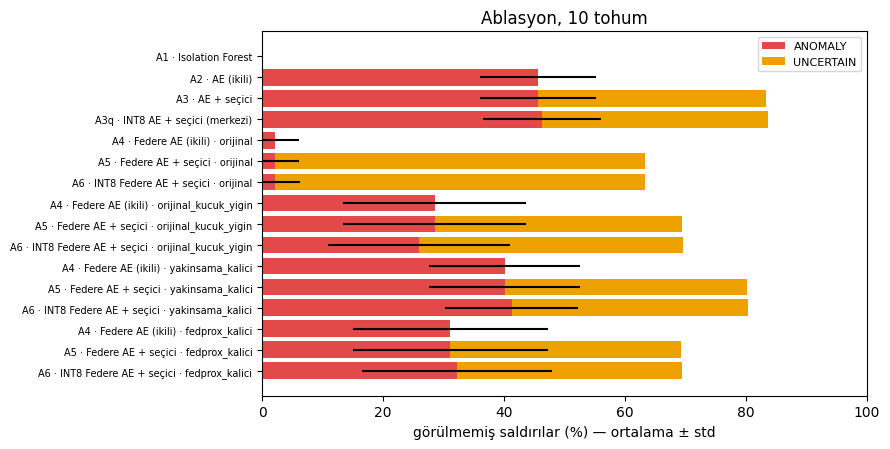

In [11]:
m_ = ABS[ABS["metrik"].isin(["görülmemiş_ANOMALY", "görülmemiş_UNCERTAIN"])].pivot_table(index="yapılandırma", columns="metrik", values="ortalama", sort=False)
s_ = ABS[ABS["metrik"].isin(["görülmemiş_ANOMALY", "görülmemiş_UNCERTAIN"])].pivot_table(index="yapılandırma", columns="metrik", values="std", sort=False)
fig, ax = plt.subplots(figsize=(9, 4.6)); y = np.arange(len(m_))
ax.barh(y, 100 * m_["görülmemiş_ANOMALY"], xerr=100 * s_["görülmemiş_ANOMALY"], color="#e34948", label="ANOMALY")
ax.barh(y, 100 * m_["görülmemiş_UNCERTAIN"], left=100 * m_["görülmemiş_ANOMALY"], color="#eda100", label="UNCERTAIN")
ax.set_yticks(y); ax.set_yticklabels(m_.index, fontsize=7); ax.invert_yaxis(); ax.set_xlim(0, 100)
ax.set_xlabel("görülmemiş saldırılar (%) — ortalama ± std"); ax.set_title(f"Ablasyon, {len(DONE)} tohum"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(RUN / f"{TAG}_ablasyon.png", dpi=150)
utils.save_json({"tohumlar": DONE, "protokoller": cfg.fl_final_protocols, "parmak_izi": FP, "öznitelik_sayısı": int(X["benign_train"].shape[1]),
                 "not": "Gecikme Colab CPU'sunda ölçüldü; mikrodenetleyici değeri değildir. GA yalnız eğitim tohumu değişkenliğini yansıtır."},
                RUN / f"{TAG}_ozet.json")
print("Sonuçlar:", RUN)

In [12]:
# Colab: Drive'a yazılan tüm dosyaların kaydedildiğinden emin ol (oturumu kapatmadan önce mutlaka çalıştırın)
print("Kaydedilen ilerleme:", utils.progress(cfg))
if IN_COLAB:
    drive.flush_and_unmount()
    print("Drive kaydedildi ve ayrıldı. Sonraki defter Drive'ı yeniden bağlar.")

Kaydedilen ilerleme: {'01_hazirlanan_veri': True, '02_tohumlar_tamam': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], '02_oznitelik_karsilastirma_tohumlari': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], '03_kararlar': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], '04b_host_eslesmesi': True}
Drive kaydedildi ve ayrıldı. Sonraki defter Drive'ı yeniden bağlar.
